### Inverse distance weighting (IDW) interpolation
This notebook reconstructs the F3 EEG channel from its neighboring electrodes (Fp1, F7, C3, and Fz) using inverse distance weighting (IDW). The weights are based on three-dimensional electrode distances and an inverse-distance power of 2. The reconstructed signal is compared with the recorded F3 signal using time-domain and frequency-domain metrics.

Run the EEG preprocessing notebook first. This notebook expects the cleaned FIF files in Processed_data and the electrode coordinates in coordinates.csv. The recorded F3 channel is used only for evaluating the reconstruction.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import coherence, welch
from scipy.spatial.distance import jensenshannon
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mutual_info_score

In [10]:
# Use paths relative to the project directory.
processed_dir = Path("Processed_data")
# Directory for saving reconstructed EEG signals.
cache_dir = processed_dir / "Reconstructed_signals"
cache_dir.mkdir(parents=True, exist_ok=True)
coordinates_path = Path("coordinates.csv")

# Reconstruct F3 for subjects sub-037 through sub-065.
subjects = range(37, 66)
target_channel = "F3"
neighbors = ["Fp1", "F7", "C3", "Fz"]

# Parameters for mutual information, spectral metrics, and IDW weights.
n_bins = 64
nperseg = 1024
power = 2

In [11]:
def normalize_label(label):
    """Standardize channel labels for coordinate lookup."""
    return str(label).strip().upper()


def load_coordinates(path):
    """Load three-dimensional electrode coordinates from a CSV file."""
    coords_df = pd.read_csv(path, sep=None, engine="python")

    required_cols = ["EEG Label", "X", "Y", "Z"]
    missing_cols = [col for col in required_cols if col not in coords_df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns in coordinate file: {missing_cols}")

    coords = {}
    for _, row in coords_df.iterrows():
        label = normalize_label(row["EEG Label"])
        coords[label] = np.array([
            float(row["X"]),
            float(row["Y"]),
            float(row["Z"]),
        ])

    return coords

In [12]:
coords = load_coordinates(coordinates_path)

# Fz was missing from the original coordinate dataset, so its coordinates
# were calculated separately during the study.
coords["FZ"] = np.array([0.673028145, 0.0, 0.5])

In [13]:
def idw_interpolation(data, ch_names, coords, target_channel, available_neighbors, power=2):
    """Reconstruct an EEG channel using inverse-distance-weighted neighboring signals."""
    target_label = normalize_label(target_channel)
    neighbor_labels = [normalize_label(ch) for ch in available_neighbors]

    # Both the target and neighboring electrodes need known coordinates.
    required_labels = [target_label] + neighbor_labels
    missing_coords = [label for label in required_labels if label not in coords]
    if missing_coords:
        raise ValueError(f"Missing coordinates for channels: {missing_coords}")

    # The recorded target channel is required only for reconstruction evaluation.
    missing_channels = [ch for ch in available_neighbors if ch not in ch_names]
    if target_channel not in ch_names:
        missing_channels.append(target_channel)
    if missing_channels:
        raise ValueError(f"Missing EEG channels: {missing_channels}")

    # Use Euclidean distances in 3D electrode-coordinate space.
    target_xyz = coords[target_label]
    distances = []
    for label in neighbor_labels:
        neighbor_xyz = coords[label]
        distances.append(np.linalg.norm(neighbor_xyz - target_xyz))
    distances = np.array(distances)

    # Avoid division by zero if two electrode positions coincide.
    if np.any(distances == 0):
        raise ValueError("Zero distance found between electrode coordinates.")

    # Normalize 1 / distance**power so that the weights sum to one.
    weights = 1 / (distances ** power)
    weights = weights / weights.sum()

    # Apply the same spatial weights to each time sample.
    neighbor_indices = [ch_names.index(ch) for ch in available_neighbors]
    neighbor_signals = data[neighbor_indices]
    interpolated = np.zeros_like(neighbor_signals[0])
    for weight, signal in zip(weights, neighbor_signals):
        interpolated += weight * signal

    return interpolated

In [14]:
def calculate_metrics(x, y, fs):
    """Compare the recorded and reconstructed EEG signals in time and frequency."""
    # Pearson correlation, its p-value, and RMSE describe time-domain similarity.
    corr, p_value = pearsonr(x, y)
    rmse = np.sqrt(mean_squared_error(x, y))

    # Estimate mutual information after binning each signal into 64 intervals.
    x_binned = np.digitize(x, np.histogram_bin_edges(x, bins=n_bins))
    y_binned = np.digitize(y, np.histogram_bin_edges(y, bins=n_bins))
    mi = mutual_info_score(x_binned, y_binned)

    # Average magnitude-squared coherence over the 1–45 Hz frequency band.
    f_coh, coh = coherence(x, y, fs=fs, nperseg=nperseg)
    coh_mask = (f_coh >= 1) & (f_coh <= 45)
    mean_coherence_1_45 = np.mean(coh[coh_mask])

    # Compare normalized power spectral densities over the same frequency band.
    f_psd, psd_x = welch(x, fs=fs, nperseg=nperseg)
    _, psd_y = welch(y, fs=fs, nperseg=nperseg)
    psd_mask = (f_psd >= 1) & (f_psd <= 45)
    psd_x_band = psd_x[psd_mask]
    psd_y_band = psd_y[psd_mask]

    # A zero-power spectrum cannot be normalized to a probability distribution.
    if psd_x_band.sum() == 0 or psd_y_band.sum() == 0:
        js_distance = np.nan
        js_divergence = np.nan
    else:
        psd_x_norm = psd_x_band / psd_x_band.sum()
        psd_y_norm = psd_y_band / psd_y_band.sum()
        js_distance = jensenshannon(psd_x_norm, psd_y_norm)
        js_divergence = js_distance ** 2

    # Keep original CSV column names for compatibility with the comparison notebook.
    return {
        "Pearsono koreliacija": corr,
        "p reikšmė": p_value,
        "RMSE": rmse,
        "Abipusė informacija": mi,
        "Vidutinė spektrinė koherencija": mean_coherence_1_45,
        "Jensen-Shannon atstumas": js_distance,
        "Jensen-Shannon divergencija": js_divergence,
    }

In [15]:
results = []

for sub in subjects:
    subject_code = f"sub-{sub:03d}"
    fif_path = processed_dir / f"{subject_code}_task-eyesclosed_eeg_cleaned_raw.fif"

    print(f"Processing {subject_code}")

    if not fif_path.exists():
        print(f"File not found: {fif_path}")
        results.append({"subjektas": subject_code, "statusas": "missing_file"})
        continue

    try:
        raw = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)
        data = raw.get_data()
        ch_names = raw.ch_names
        fs = raw.info["sfreq"]

        if target_channel not in ch_names:
            print(f"Channel not found: {target_channel}")
            results.append({"subjektas": subject_code, "statusas": "missing_F3"})
            continue

        available_neighbors = [ch for ch in neighbors if ch in ch_names]
        if len(available_neighbors) < 2:
            print("At least two neighboring channels are required for this analysis.")
            results.append({
                "subjektas": subject_code,
                "statusas": "not_enough_neighbors",
                "Kaimyniniai kanalai": ",".join(available_neighbors),
                "Kaimynų skaičius": len(available_neighbors),
            })
            continue

        # Hold out F3 from interpolation and use it as the reference signal.
        f3_original = data[ch_names.index(target_channel)].copy()
        f3_idw = idw_interpolation(
            data=data,
            ch_names=ch_names,
            coords=coords,
            target_channel=target_channel,
            available_neighbors=available_neighbors,
            power=power,
        )

        metrics = calculate_metrics(f3_original, f3_idw, fs)
        
        # Save the original and IDW reconstructed F3 signals.
        np.savez_compressed(
            cache_dir / f"{subject_code}_original.npz",
            signal=f3_original,
            fs=fs,
        )
        np.savez_compressed(
            cache_dir / f"{subject_code}_idw.npz",
            signal=f3_idw,
            fs=fs,
        )

        results.append({
            "subjektas": subject_code,
            "statusas": "ok",
            "Interpoliuojamas kanalas": target_channel,
            "Kaimyniniai kanalai": ",".join(available_neighbors),
            "Kaimynų skaičius": len(available_neighbors),
            "IDW laipsnis p": power,
            "fs": fs,
            **metrics,
        })

        print(
            f"OK | corr={metrics['Pearsono koreliacija']:.4f}, "
            f"RMSE={metrics['RMSE']:.6e}, "
            f"JSD={metrics['Jensen-Shannon divergencija']:.6f}"
        )

    except Exception as error:
        print(f"Error for {subject_code}: {error}")
        results.append({
            "subjektas": subject_code,
            "statusas": f"error: {error}",
        })

Processing sub-037
OK | corr=0.8101, RMSE=4.047266e-06, JSD=0.010564
Processing sub-038
OK | corr=0.6470, RMSE=3.851844e-06, JSD=0.016180
Processing sub-039
OK | corr=0.7097, RMSE=6.637289e-06, JSD=0.018073
Processing sub-040
OK | corr=0.5585, RMSE=6.751805e-06, JSD=0.014867
Processing sub-041
OK | corr=0.9252, RMSE=1.845285e-06, JSD=0.001237
Processing sub-042
OK | corr=0.4549, RMSE=8.338282e-06, JSD=0.067445
Processing sub-043
OK | corr=0.6035, RMSE=2.925683e-06, JSD=0.003365
Processing sub-044
OK | corr=0.9006, RMSE=2.808916e-06, JSD=0.005869
Processing sub-045
OK | corr=0.7934, RMSE=3.248342e-06, JSD=0.005558
Processing sub-046
OK | corr=0.8279, RMSE=4.638683e-06, JSD=0.010552
Processing sub-047
OK | corr=0.7959, RMSE=3.192359e-06, JSD=0.009611
Processing sub-048
OK | corr=0.5076, RMSE=7.514045e-06, JSD=0.091991
Processing sub-049
OK | corr=0.8742, RMSE=2.995537e-06, JSD=0.005136
Processing sub-050
OK | corr=0.6793, RMSE=7.226223e-06, JSD=0.041318
Processing sub-051
OK | corr=0.099

In [16]:
results_df = pd.DataFrame(results)
display(results_df)

# Save the subject-level metrics for later comparison with other methods.
output_csv = processed_dir / "F3_IDW_interpolation_metrics_all_subjects.csv"
results_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
print(f"Results saved to: {output_csv}")

,subjektas,statusas,Interpoliuojamas kanalas,Kaimyniniai kanalai,Kaimynų skaičius,IDW laipsnis p,fs,Pearsono koreliacija,p reikšmė,RMSE,Abipusė informacija,Vidutinė spektrinė koherencija,Jensen-Shannon atstumas,Jensen-Shannon divergencija
0,sub-037,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.810117,0.0,0.000004,0.540654,0.324093,0.102781,0.010564
1,sub-038,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.646984,0.0,0.000004,0.282874,0.475633,0.127200,0.016180
2,sub-039,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.709725,0.0,0.000007,0.353251,0.414247,0.134438,0.018073
3,sub-040,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.558475,0.0,0.000007,0.291858,0.378030,0.121930,0.014867
4,sub-041,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.925224,0.0,0.000002,0.972532,0.845387,0.035176,0.001237
5,sub-042,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.454947,0.0,0.000008,0.434240,0.379094,0.259702,0.067445
6,sub-043,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.603466,0.0,0.000003,0.248363,0.378360,0.058008,0.003365
7,sub-044,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.900620,0.0,0.000003,0.822330,0.700193,0.076611,0.005869
8,sub-045,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.793409,0.0,0.000003,0.582756,0.689891,0.074551,0.005558
9,sub-046,ok,F3,"Fp1,F7,C3,Fz",4,2,500.0,0.827946,0.0,0.000005,0.633568,0.456534,0.102723,0.010552


Results saved to: C:\Users\gytis\Baigiamasis\Processed_data\F3_IDW_interpolation_metrics_all_subjects.csv


### Optional signal comparison
Plot the recorded and IDW-reconstructed F3 signals for one subject over the original 20–60 s interval. This uses the same IDW function as the subject-level metric calculations.

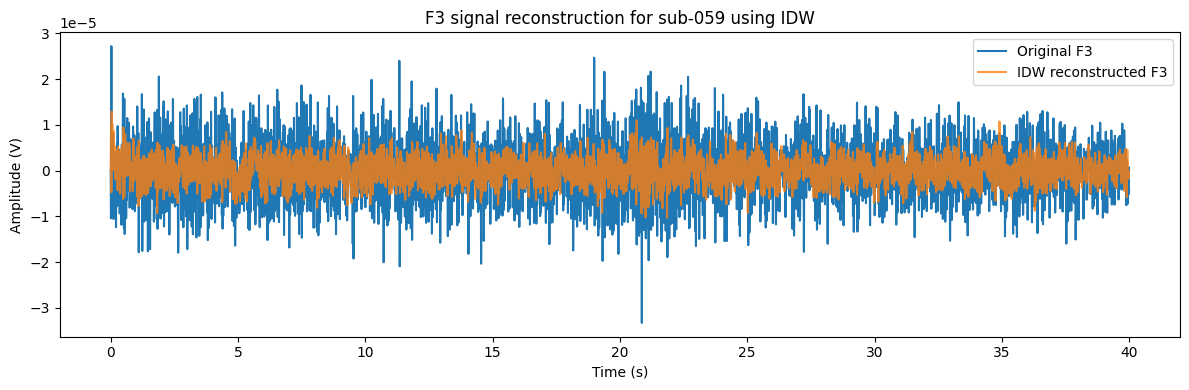

In [17]:
subject_to_plot = "sub-059"
preview_path = processed_dir / f"{subject_to_plot}_task-eyesclosed_eeg_cleaned_raw.fif"

if preview_path.exists():
    raw = mne.io.read_raw_fif(preview_path, preload=True, verbose=False)
    data = raw.get_data()
    ch_names = raw.ch_names
    fs = raw.info["sfreq"]

    available_neighbors = [ch for ch in neighbors if ch in ch_names]
    f3_original = data[ch_names.index(target_channel)]

    # Reuse the same 3D IDW interpolation as in the metrics calculation.
    f3_idw = idw_interpolation(
        data=data,
        ch_names=ch_names,
        coords=coords,
        target_channel=target_channel,
        available_neighbors=available_neighbors,
        power=power,
    )

    start_sec = 0
    end_sec = 40
    start = int(start_sec * fs)
    end = int(end_sec * fs)
    time = np.arange(start, end) / fs

    plt.figure(figsize=(12, 4))
    plt.plot(time, f3_original[start:end], label="Original F3")
    plt.plot(time, f3_idw[start:end], label="IDW reconstructed F3", alpha=0.8)
    plt.title(f"F3 signal reconstruction for {subject_to_plot} using IDW")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (V)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Preview file not found: {preview_path}")